# Analisis Simulado vs Real - Semana 36 (2026)

Compara el tiempo de viaje predicho por la simulacion contra la operacion real registrada esa semana, por linea y hora del dia.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (14, 7)
plt.rcParams['font.size'] = 10

ANIO = 2026
NUM_SEMANA = 36
LINEAS = [305, 303, 336, 301]

CARPETA_RESULTADOS = Path('..') / 'resultados' / f'semana_{NUM_SEMANA}'
RUTA_CSV_REAL = Path(f'Semana {NUM_SEMANA}.csv')


## 1. Datos simulados

In [2]:
dfs_sim = []
for linea in LINEAS:
    ruta_excel = CARPETA_RESULTADOS / f'simulacion_{linea}_semana_{NUM_SEMANA}.xlsx'
    if not ruta_excel.exists():
        print(f"[AVISO] No se encontro el excel de la linea {linea}: {ruta_excel}")
        continue
    df_linea = pd.read_excel(ruta_excel, sheet_name='resumen_viajes')
    df_linea['linea'] = linea
    dfs_sim.append(df_linea)

if dfs_sim:
    df_sim = pd.concat(dfs_sim, ignore_index=True)
    df_sim['hora'] = df_sim['hora_salida'].str.slice(0, 2).astype(int)
    sim_hourly = (
        df_sim.groupby(['linea', 'hora', 'direccion'])['tiempo_total_min']
        .mean()
        .reset_index()
        .rename(columns={'tiempo_total_min': 'tiempo_min'})
    )
else:
    sim_hourly = pd.DataFrame(columns=['linea', 'hora', 'direccion', 'tiempo_min'])

print(f"Datos simulados: {len(dfs_sim)} lineas cargadas, {len(sim_hourly)} combinaciones linea/hora/direccion")
sim_hourly.head()


Datos simulados: 4 lineas cargadas, 168 combinaciones linea/hora/direccion


,linea,hora,direccion,tiempo_min
0,301,0,ida,18.605714
1,301,0,vuelta,17.537143
2,301,4,ida,43.327857
3,301,4,vuelta,31.875000
4,301,5,ida,55.813190


## 2. Datos reales

In [3]:
COLUMNAS_REAL = [
    'fecha', 'semana', 'linea', 'sentido', 'hora_plan', 'hora_real',
    'part_plan', 'dif_plan_real', 'real_sal', 'itinerario',
    'parada_desde', 'parada_hacia', 'conductor', 'tarea',
    'patente', 'tiempo_transporte_seg',
]

if RUTA_CSV_REAL.exists():
    df_real_raw = pd.read_csv(RUTA_CSV_REAL, sep=';', encoding='latin-1',
                               names=COLUMNAS_REAL, header=0)
    df_real_raw = df_real_raw[df_real_raw['linea'].isin(LINEAS)]

    # Cada row es un arco; un viaje completo = mismo conductor+tarea en la
    # misma hora planificada (dos conductores pueden compartir hora_plan).
    viajes_real = (
        df_real_raw.groupby(['fecha', 'linea', 'sentido', 'hora_plan', 'conductor', 'tarea'])
        ['tiempo_transporte_seg'].sum()
        .reset_index()
    )
    viajes_real['hora'] = viajes_real['hora_plan'].str.slice(0, 2).astype(int)
    viajes_real['direccion'] = viajes_real['sentido'].map({1: 'ida', 2: 'vuelta'})
    viajes_real['tiempo_min'] = viajes_real['tiempo_transporte_seg'] / 60

    real_hourly = (
        viajes_real.groupby(['linea', 'hora', 'direccion'])['tiempo_min']
        .mean()
        .reset_index()
    )
    print(f"Datos reales: {len(viajes_real)} viajes cargados, {len(real_hourly)} combinaciones linea/hora/direccion")
else:
    print(f"[AVISO] No se encontro el CSV de datos reales: {RUTA_CSV_REAL.resolve()}")
    print("Se graficara solo la curva simulada.")
    real_hourly = pd.DataFrame(columns=['linea', 'hora', 'direccion', 'tiempo_min'])

real_hourly.head()


[AVISO] No se encontro el CSV de datos reales: C:\Users\IsabelMiranda\Documents\Proyectos\ETA\3_simulador_tiempos_arco\analisis\Semana 36.csv
Se graficara solo la curva simulada.


,linea,hora,direccion,tiempo_min


## 3. Graficos por linea: tiempo de viaje por hora

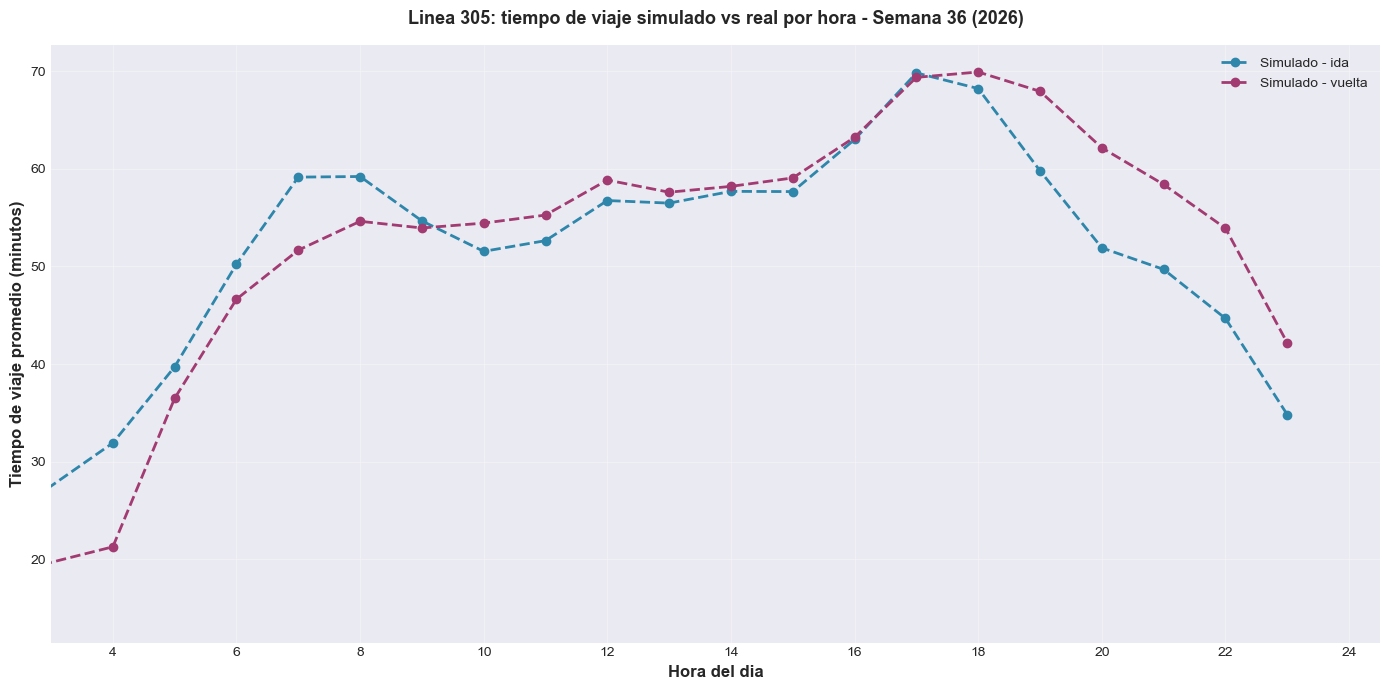

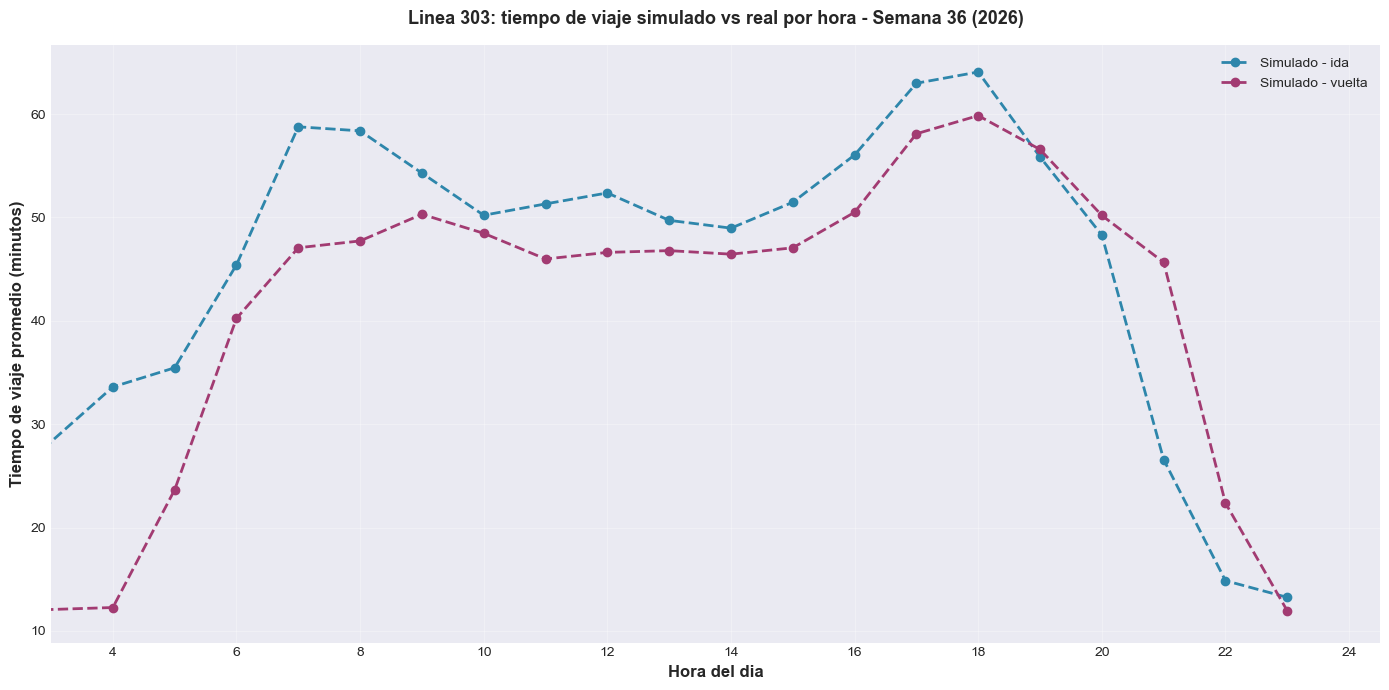

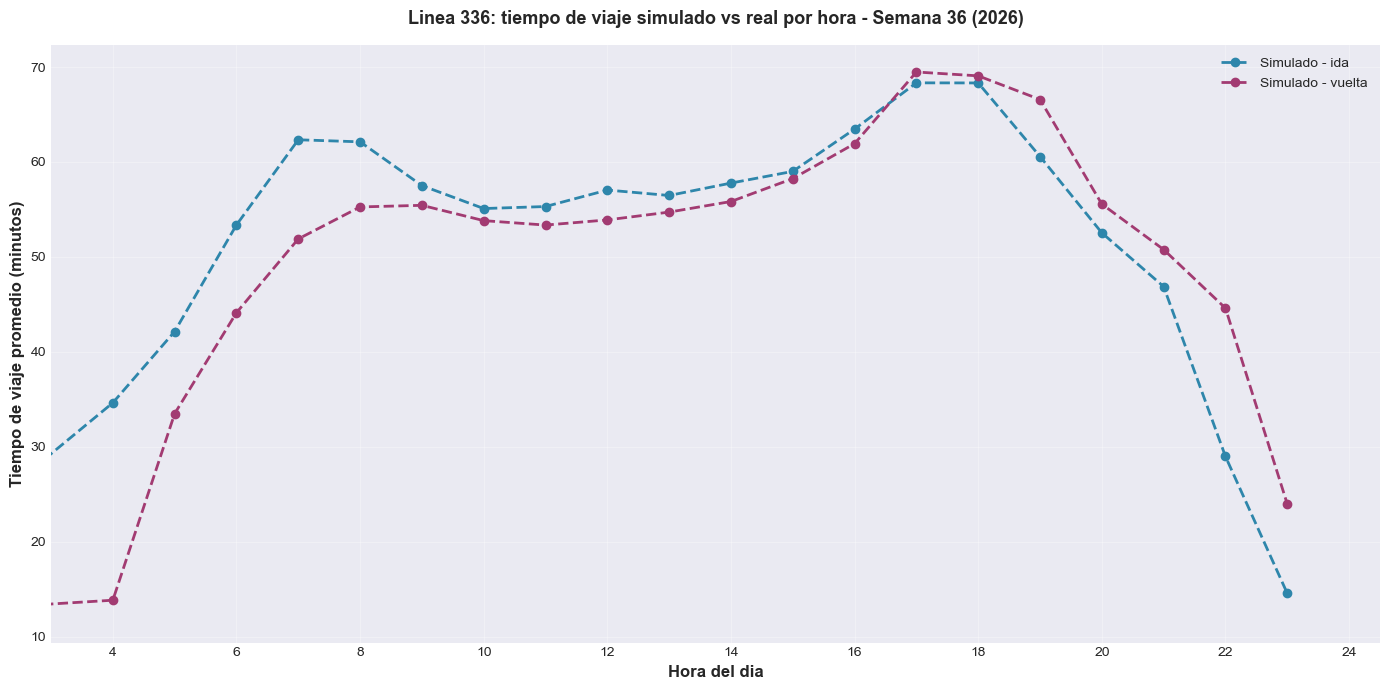

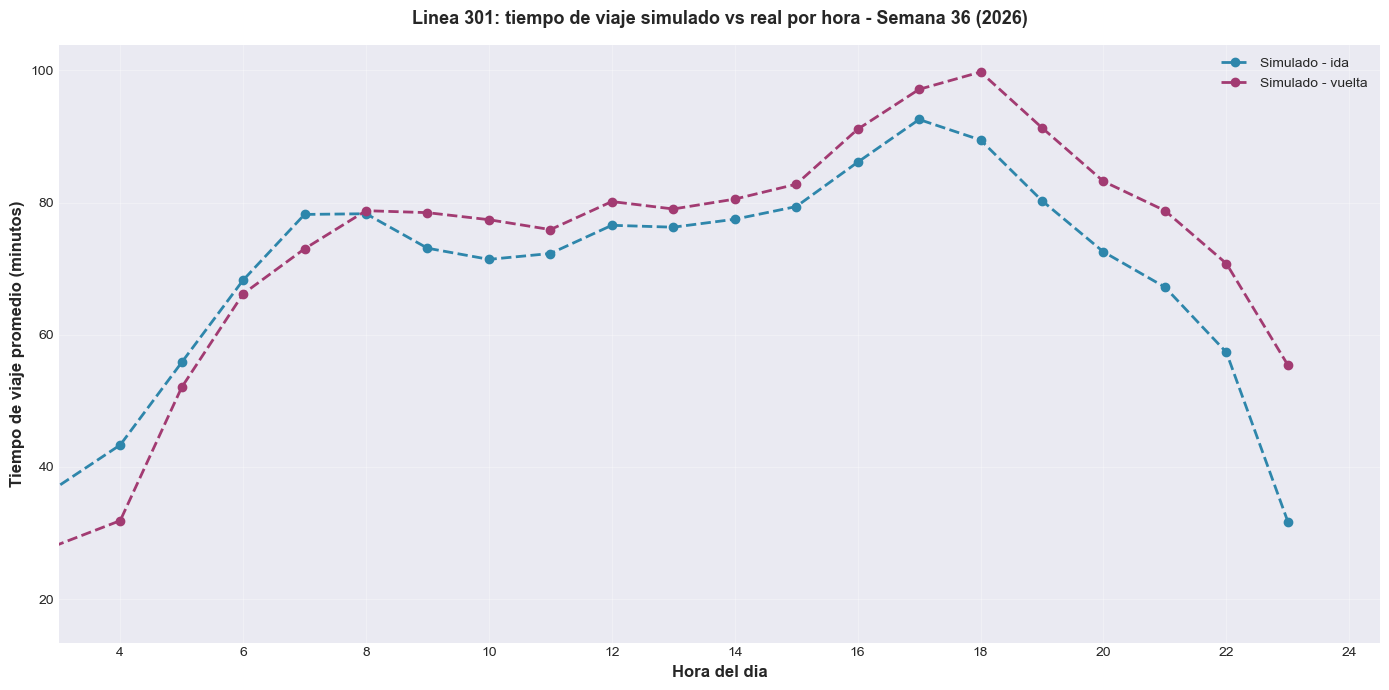

In [4]:
COLOR_SENTIDO = {'ida': '#2E86AB', 'vuelta': '#A23B72'}

for linea in LINEAS:
    fig, ax = plt.subplots(figsize=(14, 7))

    for direccion, color in COLOR_SENTIDO.items():
        sim_d = sim_hourly[(sim_hourly['linea'] == linea) & (sim_hourly['direccion'] == direccion)].sort_values('hora')
        if not sim_d.empty:
            ax.plot(sim_d['hora'], sim_d['tiempo_min'], marker='o', linestyle='--',
                    linewidth=2, color=color, label=f'Simulado - {direccion}')

        real_d = real_hourly[(real_hourly['linea'] == linea) & (real_hourly['direccion'] == direccion)].sort_values('hora')
        if not real_d.empty:
            ax.plot(real_d['hora'], real_d['tiempo_min'], marker='s', linestyle='-',
                    linewidth=2, color=color, label=f'Real - {direccion}')

    ax.set_xlabel('Hora del dia', fontsize=12, fontweight='bold')
    ax.set_ylabel('Tiempo de viaje promedio (minutos)', fontsize=12, fontweight='bold')
    ax.set_title(f'Linea {linea}: tiempo de viaje simulado vs real por hora - Semana {NUM_SEMANA} ({ANIO})',
                 fontsize=13, fontweight='bold', pad=15)
    ax.set_xticks(range(0, 25, 2))
    ax.set_xlim(3, 24.5)
    ax.legend(fontsize=10, loc='best')
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()
